# HCC external validation — pan-cancer Hist2Pheno

Seven HE JPEGs (`P1_N`, `P1_T`, `P2_N`, `P3_T`, `P5_N`, `P5_T`, `P7_T`), StarDist nuclei, **no cell-type ground truth** and no 10x JSON.
Predictions are the pan-cancer **cross-section** checkpoint
`D_emph_L2_spatial_pancancer` (L1 / L12 / L2), spatial k=8.

The JPEGs have **no OME PhysicalSize**. 96 dpi is a Windows Photo Viewer placeholder.
The finished run used **`MPP_UM = 0.5`** (`HCC.log`). At that value a native 16 px crop is already **8 µm**, so `scale_image` is false.
This notebook uses 0.5 unless the kernel was started with a different `MPP_UM`.

```bash
cd /home/lingyu/ssd2/Python/Hist2Pheno
export MPP_UM=0.5   # replace with the real scanner µm/px
bash code/External_val/HCC/demo.sh dry-run
bash code/External_val/HCC/demo.sh all
```

Outputs: `data/Visium/HCC/pred_pancancer_section/`.


In [8]:
import os
import sys
from pathlib import Path

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code"))

from Hist2Pheno_pkg.external_validation import ExternalCohort

# Finished demo.sh run (code/External_val/HCC/HCC.log). Override only if you
# re-extract features with a different scanner calibration.
MPP_UM = float(os.environ.get("MPP_UM", "0.5"))

_cohort = ExternalCohort(
    name="HCC",
    data_root=REPO / "data" / "Visium" / "HCC",
    repo=REPO,
    he_suffix=".jpg",
    mpp_um=MPP_UM,
)
PRED_ROOT = _cohort.pred_root
composition_table = _cohort.composition_table
discover_samples = _cohort.discover_samples
geometry = _cohort.geometry
sample_paths = _cohort.sample_paths
ensure_l2_probs = _cohort.ensure_l2_probs
plot_spatial = _cohort.plot_spatial
plot_composition = _cohort.plot_composition
# Re-run the plot cell after changing these. Notebook display uses DPI; saved PNGs use SAVE_DPI.
SAVE_FIGURES = False
FIGSIZE = (17.2, 6.6)
DPI = 200
SAVE_DPI = 300
HE_MAX_SIDE = 1400
MARKER_PX = 1.5

samples = discover_samples()
for sample in samples:
    g = geometry(sample)
    print(
        f"{sample}  mpp={g['mpp_um']:.4f} µm/px  "
        f"native16={g['patch_um_if_native_16px']:.2f} µm  "
        f"after rescale={g['patch_um_after_rescale']:.1f} µm  "
        f"scale={g['scale']:.4f}"
    )
    p = sample_paths(sample)
    print(f"  pred exists: {p['pred'].is_file()}  {p['pred']}")


P1_N  mpp=0.5000 µm/px  native16=8.00 µm  after rescale=8.0 µm  scale=1.0000
  pred exists: True  /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/pred_pancancer_section/P1_N/P1_N_stardist_pred.h5ad
P1_T  mpp=0.5000 µm/px  native16=8.00 µm  after rescale=8.0 µm  scale=1.0000
  pred exists: True  /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/pred_pancancer_section/P1_T/P1_T_stardist_pred.h5ad
P2_N  mpp=0.5000 µm/px  native16=8.00 µm  after rescale=8.0 µm  scale=1.0000
  pred exists: True  /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/pred_pancancer_section/P2_N/P2_N_stardist_pred.h5ad
P3_T  mpp=0.5000 µm/px  native16=8.00 µm  after rescale=8.0 µm  scale=1.0000
  pred exists: True  /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/pred_pancancer_section/P3_T/P3_T_stardist_pred.h5ad
P5_N  mpp=0.5000 µm/px  native16=8.00 µm  after rescale=8.0 µm  scale=1.0000
  pred exists: True  /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/pred_pancancer_section/P5_N/P5_N_stardist_

In [2]:
import pandas as pd
from IPython.display import Image, display

missing = [s for s in samples if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        "No predictions yet for "
        + ", ".join(missing)
        + ". Run: MPP_UM=... bash code/External_val/HCC/demo.sh all"
    )

comp = composition_table(samples)

for head in ("L1", "L12", "L2"):
    sub = comp.loc[comp["head"] == head].copy()
    order = sub.groupby("class")["fraction"].max().sort_values(ascending=False).index
    wide = (
        sub.pivot_table(index="class", columns="sample", values=["fraction", "n", "mean_conf"])
        .reindex(order)
    )
    print(f"\n===== {head} =====")
    display(wide.round(3))



===== L1 =====


fraction                                           mean_conf  \
sample          P1_N   P1_T   P2_N   P3_T   P5_N   P5_T   P7_T      P1_N   
class                                                                      
Endothelial    0.624  0.458  0.478  0.341  0.431  0.427  0.360     0.454   
Immune         0.160  0.258  0.408  0.529  0.392  0.490  0.153     0.435   
Stromal        0.212  0.162  0.102  0.103  0.176  0.084  0.414     0.443   
Epithelial     0.004  0.122  0.012  0.028  0.001  0.000  0.073     0.448   

                           ...                             n           \
sample        P1_T   P2_N  ...   P5_N   P5_T   P7_T     P1_N     P1_T   
class                      ...                                          
Endothelial  0.430  0.454  ...  0.416  0.409  0.415  83699.0  81018.0   
Immune       0.393  0.463  ...  0.408  0.406  0.391  21522.0  45572.0   
Stromal      0.433  0.424  ...  0.384  0.369  0.450  28407.0  28705.0   
Epithelial   0.452  0.435  ...  0.451  0.388  0.451    527.0  21534.0   

                                                            
sample           P2_N     P3_T     P5_N     P5_T      P7_T  
class                                                       
Endothelial  120841.0  60546.0  76946.0  69988.0   92773.0  
Immune       102951.0  94051.0  70011.0  80327.0   39476.0  
Stromal       25801.0  18269.0  31375.0  13750.0  106665.0  
Epithelial     3011.0   4920.0    173.0      2.0   18906.0  

[4 rows x 21 columns]


===== L12 =====


fraction                                           mean_conf  \
sample          P1_N   P1_T   P2_N   P3_T   P5_N   P5_T   P7_T      P1_N   
class                                                                      
Myeloid        0.444  0.739  0.710  0.823  0.629  0.555  0.499     0.315   
Stromal        0.429  0.201  0.159  0.107  0.109  0.046  0.444     0.344   
T_cell         0.048  0.029  0.090  0.047  0.254  0.391  0.027     0.296   
Endothelial    0.044  0.018  0.025  0.010  0.006  0.006  0.007     0.304   
B_Plasma       0.030  0.002  0.010  0.006  0.001  0.001  0.002     0.285   
Epithelial     0.005  0.010  0.005  0.007    NaN    NaN  0.020     0.404   
Tumor            NaN  0.001  0.000  0.000  0.000    NaN  0.000       NaN   

                           ...                             n            \
sample        P1_T   P2_N  ...   P5_N   P5_T   P7_T     P1_N      P1_T   
class                      ...                                           
Myeloid      0.449  0.403  ...  0.333  0.313  0.423  59587.0  130727.0   
Stromal      0.371  0.343  ...  0.307  0.295  0.380  57597.0   35504.0   
T_cell       0.330  0.347  ...  0.330  0.346  0.303   6498.0    5198.0   
Endothelial  0.332  0.320  ...  0.313  0.298  0.299   5841.0    3171.0   
B_Plasma     0.273  0.300  ...  0.281  0.252  0.262   3990.0     272.0   
Epithelial   0.401  0.390  ...    NaN    NaN  0.432    642.0    1853.0   
Tumor        0.491  0.457  ...  0.566    NaN  0.449      NaN     104.0   

                                                              
sample           P2_N      P3_T      P5_N     P5_T      P7_T  
class                                                         
Myeloid      179325.0  146323.0  112355.0  91117.0  128743.0  
Stromal       40215.0   19061.0   19476.0   7602.0  114365.0  
T_cell        22828.0    8309.0   45319.0  64081.0    7063.0  
Endothelial    6349.0    1763.0    1145.0   1055.0    1814.0  
B_Plasma       2499.0    1032.0     129.0    212.0     596.0  
Epithelial     1386.0    1294.0       NaN      NaN    5236.0  
Tumor             2.0       4.0      81.0      NaN       3.0  

[7 rows x 21 columns]


===== L2 =====


fraction                                            \
sample                P1_N   P1_T   P2_N   P3_T   P5_N   P5_T   P7_T   
class                                                                  
Plasma               0.667  0.129  0.394  0.429  0.581  0.570  0.174   
Macrophage           0.025  0.401  0.267  0.314  0.116  0.049  0.228   
Fibroblast           0.111  0.181  0.059  0.068  0.091  0.129  0.376   
Endothelial          0.164  0.186  0.149  0.070  0.111  0.112  0.126   
CD4_T                0.003  0.005  0.031  0.012  0.085  0.041  0.005   
Neutrophil           0.000  0.013  0.050  0.049  0.007  0.004  0.001   
Tregs                0.000  0.000  0.000  0.000  0.002  0.047  0.000   
B_cell               0.010  0.033  0.031  0.038  0.005  0.046  0.031   
Injury_epithelial    0.005  0.005  0.003  0.002    NaN  0.000  0.029   
Myofibroblast        0.011  0.022  0.007  0.005  0.001  0.000  0.019   
Epithelial           0.002  0.013  0.004  0.008  0.000    NaN  0.009   
Tumor                  NaN  0.005  0.000  0.000  0.002    NaN  0.000   
CD8_T                0.000  0.005  0.004  0.002  0.000  0.000  0.000   
DC                     NaN  0.001  0.000  0.000  0.000  0.000  0.002   
NK                   0.000  0.001  0.000  0.000  0.000    NaN  0.000   
Stromal              0.001  0.000  0.000  0.001    NaN    NaN    NaN   
Alveolar             0.000  0.000  0.000    NaN  0.000    NaN  0.000   

                  mean_conf                ...                             n  \
sample                 P1_N   P1_T   P2_N  ...   P5_N   P5_T   P7_T     P1_N   
class                                      ...                                 
Plasma                0.297  0.224  0.265  ...  0.245  0.233  0.253  89526.0   
Macrophage            0.219  0.268  0.244  ...  0.192  0.166  0.271   3403.0   
Fibroblast            0.273  0.261  0.242  ...  0.188  0.169  0.279  14866.0   
Endothelial           0.255  0.231  0.238  ...  0.203  0.190  0.223  21995.0   
CD4_T                 0.223  0.172  0.225  ...  0.197  0.148  0.193    409.0   
Neutrophil            0.199  0.244  0.282  ...  0.230  0.224  0.240     24.0   
Tregs                 0.181  0.163  0.189  ...  0.168  0.179  0.180     18.0   
B_cell                0.209  0.218  0.220  ...  0.190  0.164  0.236   1349.0   
Injury_epithelial     0.243  0.219  0.218  ...    NaN  0.171  0.274    686.0   
Myofibroblast         0.230  0.189  0.219  ...  0.189  0.199  0.210   1521.0   
Epithelial            0.332  0.249  0.253  ...  0.128    NaN  0.250    244.0   
Tumor                   NaN  0.347  0.314  ...  0.389    NaN  0.332      NaN   
CD8_T                 0.166  0.218  0.227  ...  0.155  0.146  0.187      2.0   
DC                      NaN  0.196  0.172  ...  0.166  0.148  0.215      NaN   
NK                    0.183  0.163  0.177  ...  0.116    NaN  0.153      5.0   
Stromal               0.327  0.398  0.333  ...    NaN    NaN    NaN    100.0   
Alveolar              0.194  0.186  0.193  ...  0.194    NaN  0.209      7.0   

                                                                          
sample                P1_T     P2_N     P3_T      P5_N     P5_T     P7_T  
class                                                                     
Plasma             22771.0  99484.0  76259.0  103671.0  93511.0  44960.0  
Macrophage         70825.0  67425.0  55887.0   20681.0   8045.0  58707.0  
Fibroblast         31952.0  14893.0  12168.0   16300.0  21238.0  96885.0  
Endothelial        32834.0  37733.0  12375.0   19763.0  18347.0  32446.0  
CD4_T                910.0   7849.0   2091.0   15095.0   6794.0   1228.0  
Neutrophil          2282.0  12685.0   8781.0    1266.0    697.0    303.0  
Tregs                 57.0     51.0     11.0     329.0   7771.0     41.0  
B_cell              5793.0   7779.0   6781.0     933.0   7543.0   7930.0  
Injury_epithelial    952.0    695.0    384.0       NaN      4.0   7547.0  
Myofibroblast       3893.0   1729.0    957.0     156.0     21.0   4778.0  
E

[plot] P1_N  nuclei=134,155  neighbor=12.7px  figsize=(17.2, 12.54)  dpi=200  marker_px=1.5  rows=HE+points
[plot] P1_T  nuclei=176,829  neighbor=16.0px  figsize=(17.2, 12.54)  dpi=200  marker_px=1.5  rows=HE+points
[plot] P2_N  nuclei=252,604  neighbor=12.8px  figsize=(17.2, 12.54)  dpi=200  marker_px=1.5  rows=HE+points
[plot] P3_T  nuclei=177,786  neighbor=13.1px  figsize=(17.2, 12.54)  dpi=200  marker_px=1.5  rows=HE+points
[plot] P5_N  nuclei=178,505  neighbor=19.7px  figsize=(17.2, 12.54)  dpi=200  marker_px=1.5  rows=HE+points
[plot] P5_T  nuclei=164,067  neighbor=18.2px  figsize=(17.2, 12.54)  dpi=200  marker_px=1.5  rows=HE+points
[plot] P7_T  nuclei=257,820  neighbor=14.5px  figsize=(17.2, 12.54)  dpi=200  marker_px=1.5  rows=HE+points


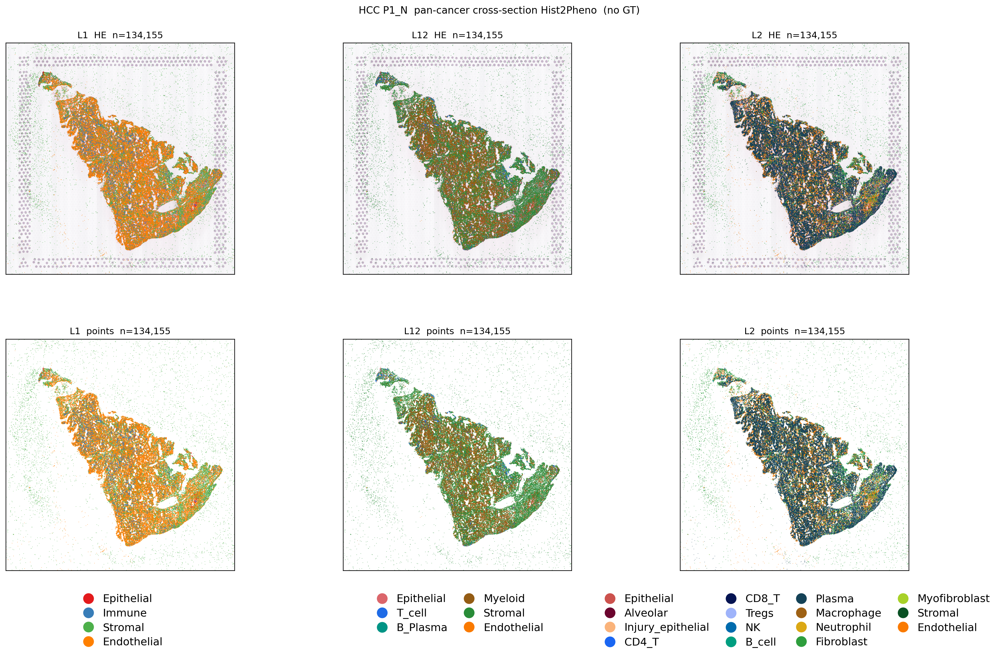

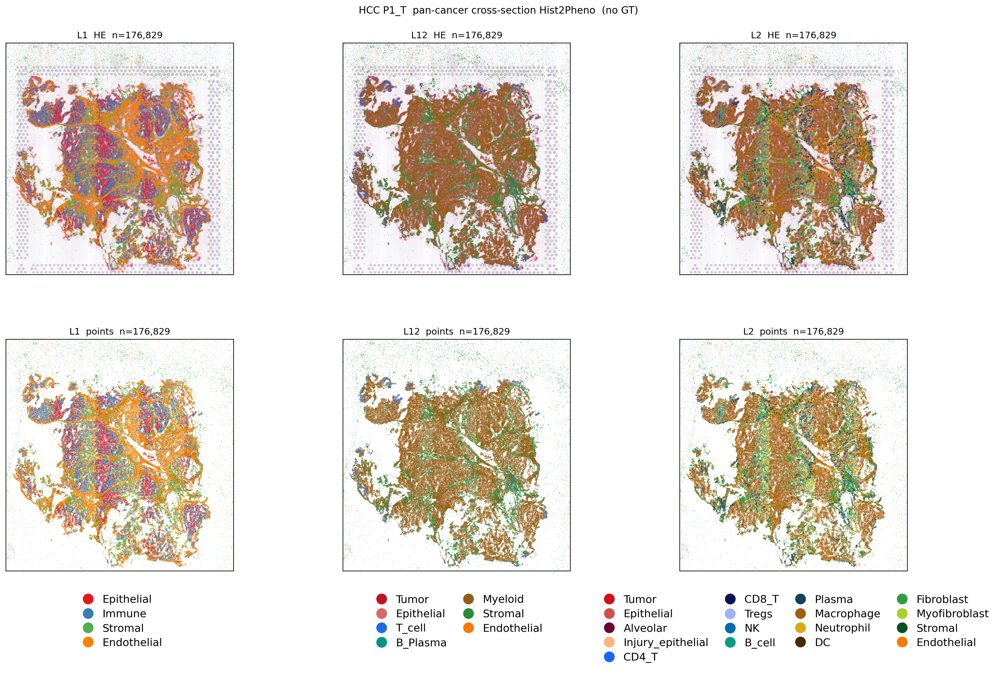

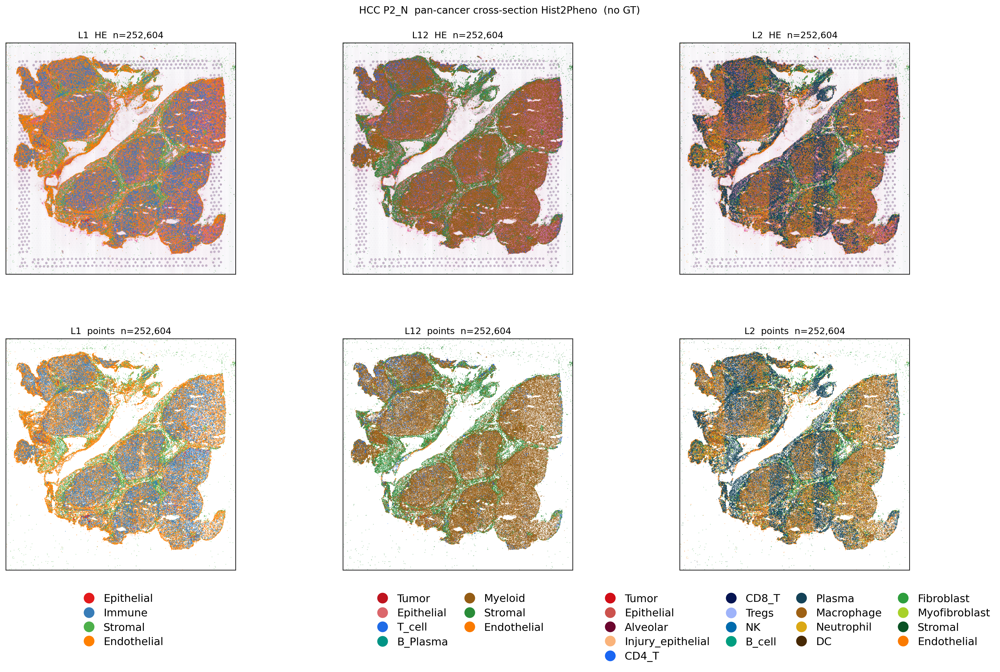

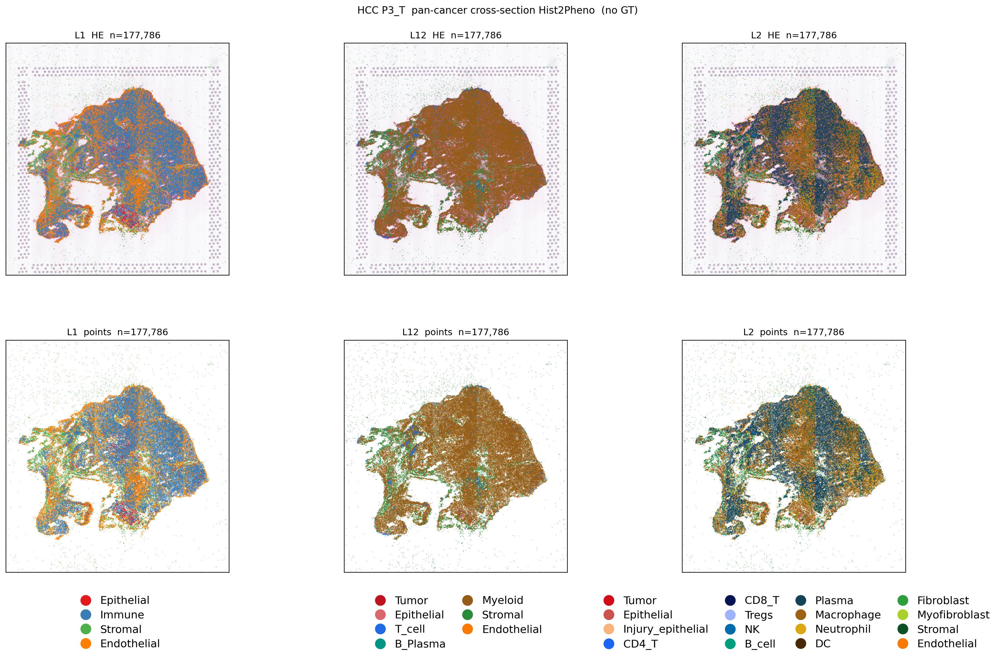

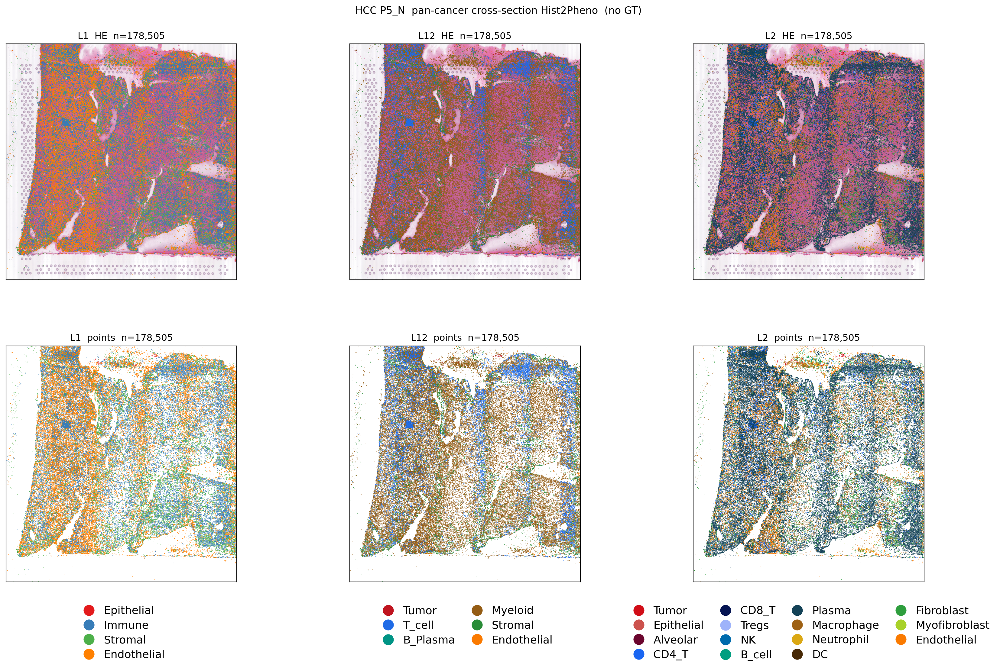

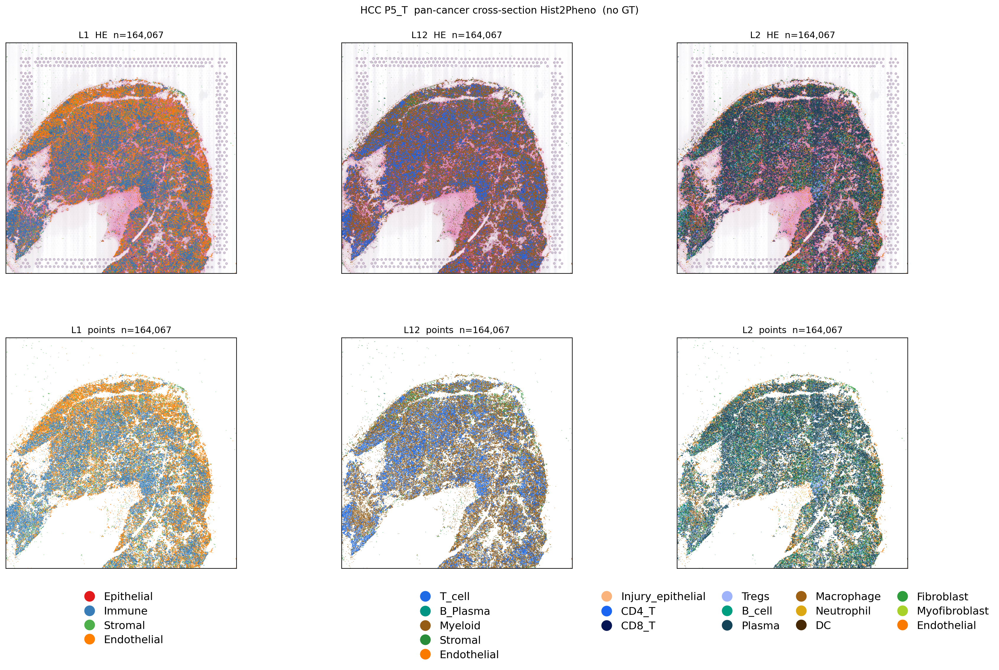

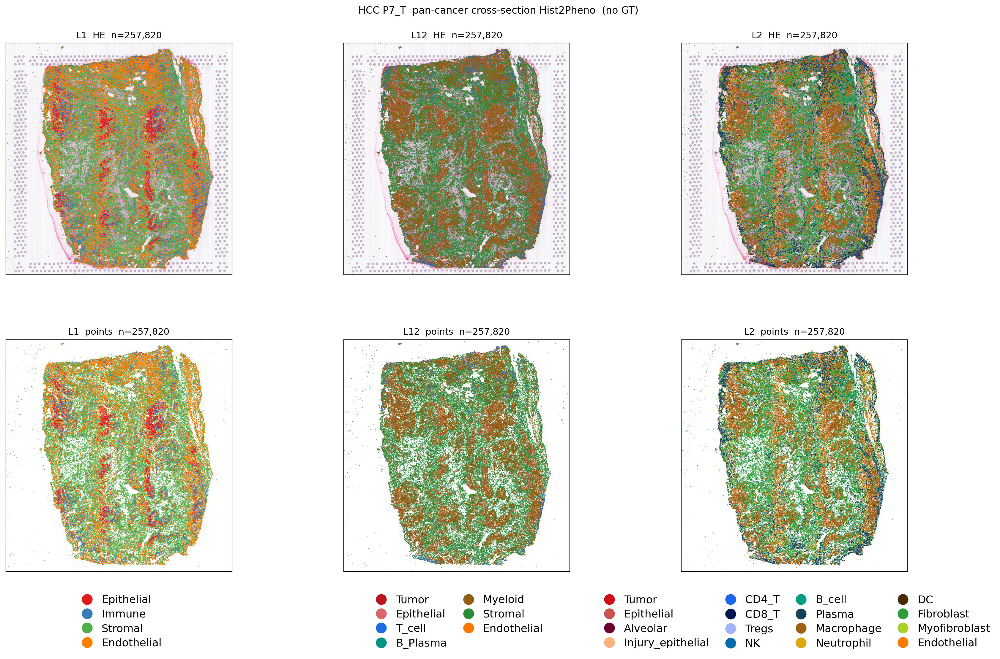

In [9]:
import matplotlib.pyplot as plt

for fig in plot_spatial(
    samples,
    figsize=FIGSIZE,
    dpi=DPI,
    he_max_side=HE_MAX_SIDE,
    marker_px=MARKER_PX,
    save=SAVE_FIGURES,
    save_dpi=SAVE_DPI,
):
    display(fig)
    plt.close(fig)


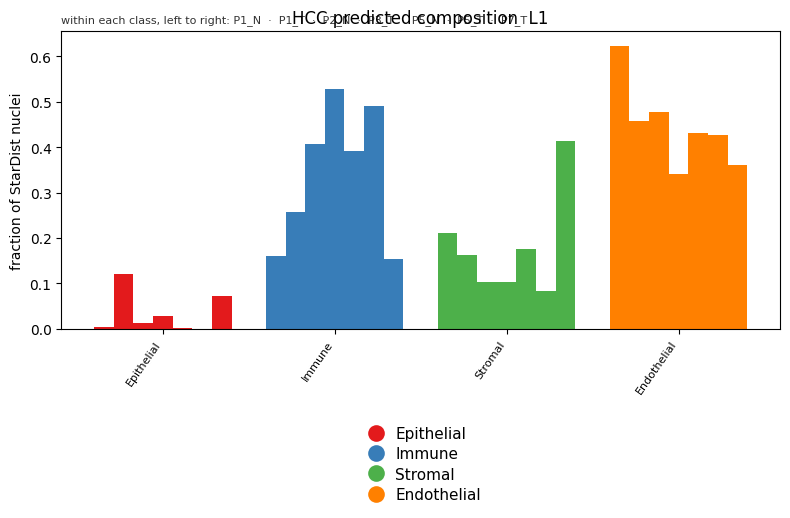

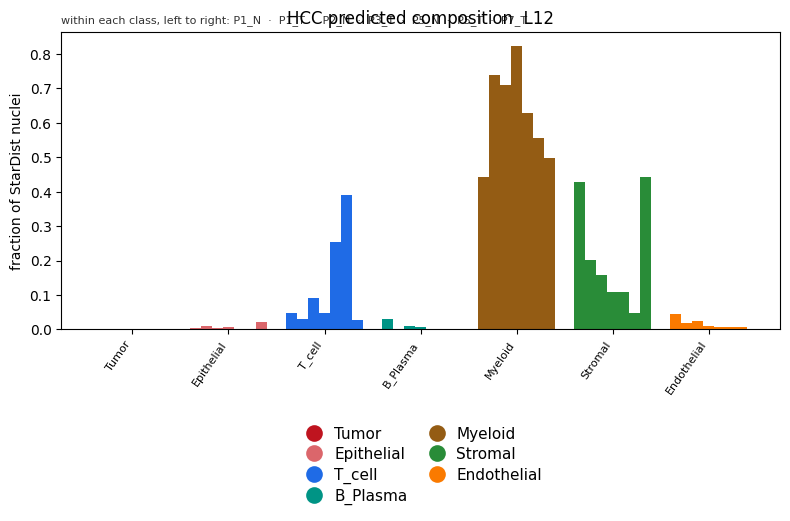

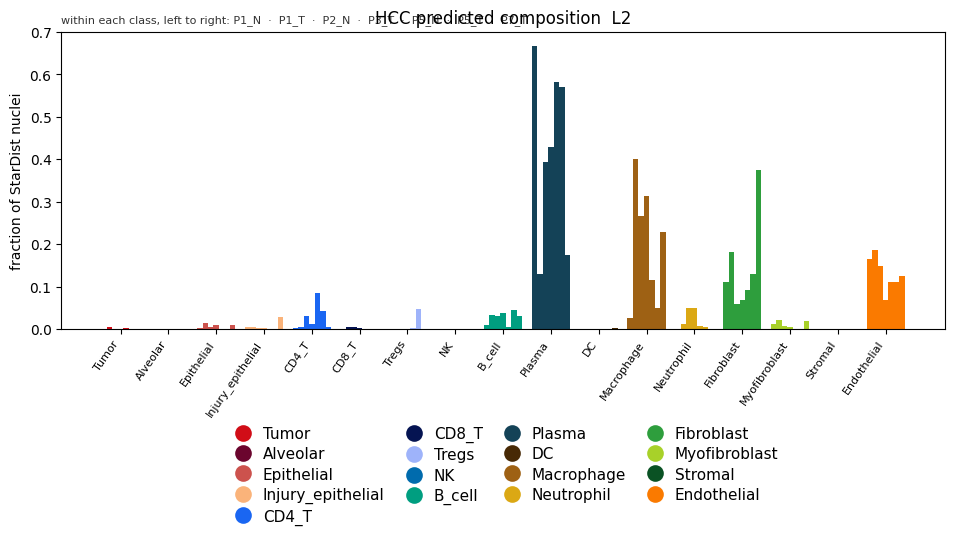

In [4]:
for fig in plot_composition(samples, save=SAVE_FIGURES, dpi=DPI, save_dpi=SAVE_DPI):
    display(fig)
    plt.close(fig)


## Histology-derived niche indices (TLS / SRI / TNI)

Same implementation as `code/Xenium_lung/histology_derived_niche_index.ipynb` §3, via `Hist2Pheno_pkg/histology_niche_index.py`. Lung ARI / FRI are not used.

Scores use **L2 softmax**, not the argmax label. `ensure_l2_probs` caches `{sample}_l2_probs.npz`.

| Index | Abundance | Spatial (radius R) |
|--|--|--|
| **TLS** | sum(B_cell + Plasma + CD4_T + CD8_T + Tregs + DC) | `(B_local × T_local × DC_local)^(1/3)` |
| **SRI** | (Fibroblast + Myofibroblast + Stromal) / epithelium | Fib_local / Epi_local |
| **TNI** | (fibroblast + Macrophage + Endothelial) / epithelium | `(Fib × Mac × Endo)^(1/3) / Epi_local` |

Epithelium = Epithelial, Tumor, Alveolar, Injury_epithelial, DCIS, Myoepithelial. NK is left out of TLS. `spatial_HE` is native JPEG pixels, so R = **55 µm** is converted with `MPP_UM`, not with 96 dpi and not with 0.5 unless that is the value you set. TLS, SRI, and TNI each use a 1×3 row: abundance, spatial score without markers, then the same spatial map with cyan candidates.


In [5]:
import importlib

for _p in (REPO / "code" / "Hist2Pheno_pkg", REPO / "code" / "Xenium_lung"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import histology_niche_index as hni
importlib.reload(hni)
import histology_derived_niche_index as hdni
importlib.reload(hdni)
from histology_niche_index import OrganNicheConfig

import anndata as ad

TLS_RADIUS_UM = 55.0
RECOMPUTE_NICHE = False

HCC_NICHE = OrganNicheConfig(
    pan_organ="pancancer_hcc",
    tls_b=("B_cell", "Plasma"),
    tls_t=("CD4_T", "CD8_T", "Tregs"),
    tls_dc=("DC",),
    epithelium=(
        "Epithelial", "Tumor", "Alveolar",
        "Injury_epithelial", "DCIS", "Myoepithelial",
    ),
    fibroblast=("Fibroblast", "Myofibroblast", "Stromal"),
    endothelial=("Endothelial",),
    macrophage=("Macrophage",),
    um_per_he_pixel=float(geometry(samples[0])["mpp_um"]),
    spatial_radius_um=TLS_RADIUS_UM,
    cohort="HCC",
)
display(hni.index_formula_table(HCC_NICHE))


,index,formula
0,TLS,sum(B_cell+ Plasma+ CD4_T+ CD8_T+ Tregs+ DC)
1,TLS_spatial,(B_local × T_local × DC_local)^(1/3) within ra...
2,SRI_ratio,Fibroblast+Myofibroblast+Stromal / Epithelial+...
3,SRI_spatial,Fib_local / Epi_local within radius R μm
4,TNI_ratio,(Fibroblast+Myofibroblast+Stromal + Macrophage...
5,TNI_spatial,(Fib_local × myeloid_local × Endo_local)^(1/3)...


In [6]:
import numpy as np
niche_frames = {}
for sample in samples:
    paths = sample_paths(sample)
    niche_path = paths["pred"].with_name(f"{sample}_niche_indices.h5ad")
    mpp = float(geometry(sample)["mpp_um"])
    if niche_path.is_file() and not RECOMPUTE_NICHE:
        cached = ad.read_h5ad(niche_path)
        df = cached.obs.copy()
        xy = np.asarray(cached.obsm["spatial_HE"], dtype=np.float64)
        df["coord_x"] = xy[:, 0]
        df["coord_y"] = xy[:, 1]
        print(f"[niche] cache {niche_path.name}  n={len(df):,}  µm/px={mpp:.4f}")
    else:
        probs, class_names = ensure_l2_probs(sample)
        missing = hni.missing_index_cell_types(class_names, HCC_NICHE)
        if missing:
            raise RuntimeError(f"{sample} missing niche compartments: {missing}")
        pred = ad.read_h5ad(paths["pred"])
        coords = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
        df = pred.obs.copy()
        df["coord_x"] = coords[:, 0]
        df["coord_y"] = coords[:, 1]
        df = hni.add_abundance_indices(df, probs, class_names, HCC_NICHE)
        df = hni.add_spatial_indices(
            df, probs, class_names, coords, HCC_NICHE,
            radius_um=TLS_RADIUS_UM,
            um_per_pixel=mpp,
        )
        out = ad.AnnData(obs=df.drop(columns=["coord_x", "coord_y"]))
        out.obsm["spatial_HE"] = coords
        out.uns["tls_radius_um"] = TLS_RADIUS_UM
        out.uns["um_per_px"] = mpp
        out.write_h5ad(niche_path)
        print(f"[niche] wrote {niche_path}  n={len(df):,}")
    niche_frames[sample] = df
    print(f"  TLS hotspot: {hni.summarize_tls_hotspots(df)}")
    print(
        f"  mean TLS={df['idx_TLS'].mean():.3f}  TLS_spatial={df['idx_TLS_spatial'].mean():.3f}  "
        f"SRI={df['idx_SRI_ratio'].mean():.3f}  TNI={df['idx_TNI_ratio'].mean():.3f}"
    )


[niche] cache P1_N_niche_indices.h5ad  n=134,155  µm/px=0.5000
  TLS hotspot: {'n_cells_total': 134155, 'n_candidate_cells': 6708, 'fraction_candidate': 0.05000186351608214, 'max_tls_spatial': 0.13548904477622753, 'mean_tls_spatial_candidate': 0.09975253492878859, 'centroid_x': 7917.479498400174, 'centroid_y': 8498.675246278179}
  mean TLS=0.329  TLS_spatial=0.073  SRI=7.450  TNI=16.624
[niche] cache P1_T_niche_indices.h5ad  n=176,829  µm/px=0.5000
  TLS hotspot: {'n_cells_total': 176829, 'n_candidate_cells': 8842, 'fraction_candidate': 0.050003110349546735, 'max_tls_spatial': 0.16618843371438016, 'mean_tls_spatial_candidate': 0.13265707247459396, 'centroid_x': 8227.98337000955, 'centroid_y': 9010.497982318653}
  mean TLS=0.278  TLS_spatial=0.086  SRI=3.983  TNI=10.616
[niche] cache P2_N_niche_indices.h5ad  n=252,604  µm/px=0.5000
  TLS hotspot: {'n_cells_total': 252604, 'n_candidate_cells': 12631, 'fraction_candidate': 0.050003167012398854, 'max_tls_spatial': 0.17359093616206123, 'mea

/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/pred_pancancer_section/figures/tls_score_summary.csv


,sample,n,TLS_mean,TLS_median,TLS_p95,TLS_max,TLS_spatial_mean,TLS_spatial_median,TLS_spatial_p95,TLS_spatial_max,pearson,spearman,top5_jaccard,abundance_top5_also_spatial_top5,TLS_spatial_mean_in_abundance_top5,TLS_mean_in_spatial_top5
0,P1_N,134155,0.329,0.331,0.475,0.774,0.073,0.074,0.093,0.135,0.427,0.376,0.088,0.162,0.083,0.392
1,P1_T,176829,0.278,0.274,0.471,0.877,0.086,0.084,0.125,0.166,0.675,0.674,0.168,0.288,0.114,0.427
2,P2_N,252604,0.303,0.299,0.467,0.841,0.083,0.083,0.106,0.174,0.458,0.446,0.110,0.198,0.095,0.400
3,P3_T,177786,0.318,0.319,0.459,0.909,0.089,0.089,0.111,0.169,0.558,0.525,0.161,0.277,0.105,0.418
4,P5_N,178505,0.390,0.391,0.506,0.855,0.114,0.115,0.135,0.170,0.610,0.470,0.133,0.235,0.126,0.470
5,P5_T,164067,0.402,0.405,0.484,0.675,0.115,0.117,0.131,0.160,0.475,0.280,0.094,0.172,0.121,0.441
6,P7_T,257820,0.272,0.266,0.469,0.871,0.079,0.077,0.121,0.168,0.643,0.635,0.177,0.301,0.108,0.425


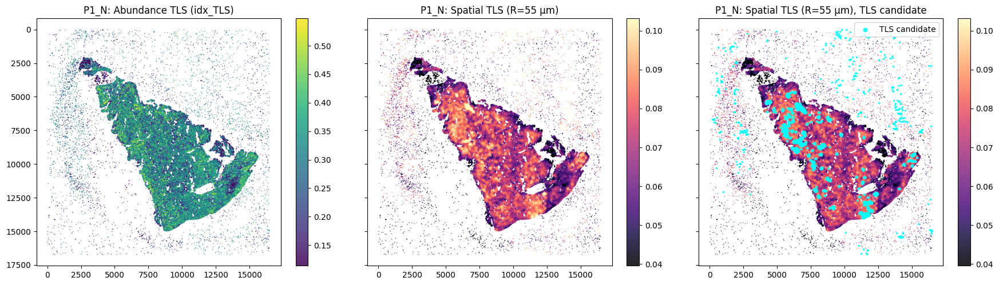

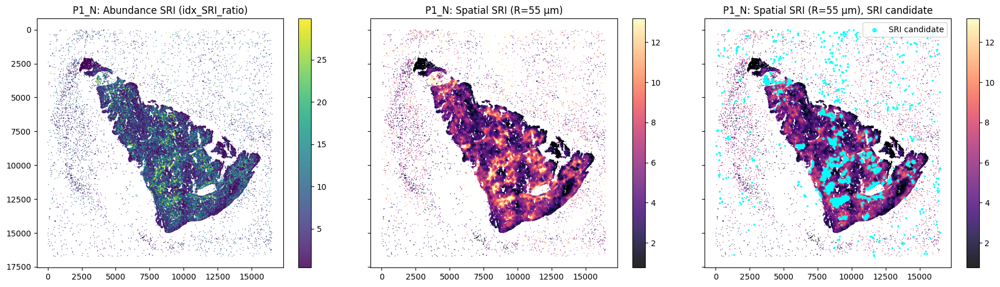

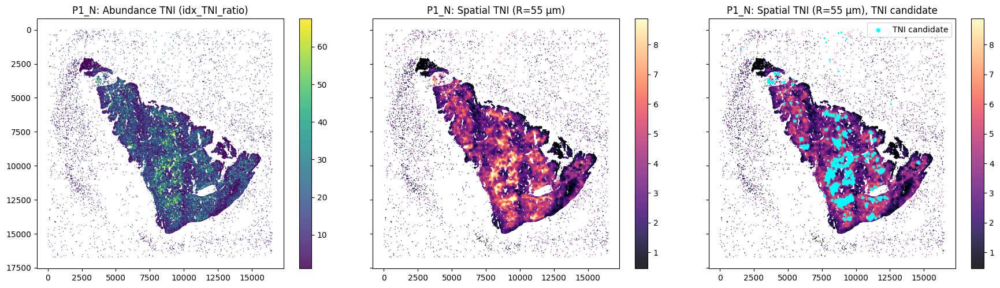

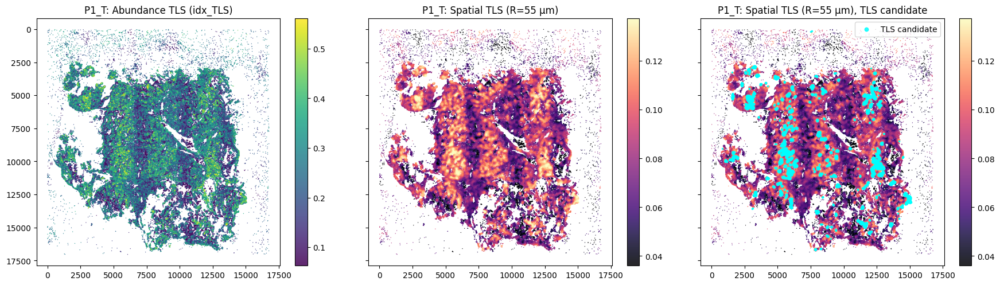

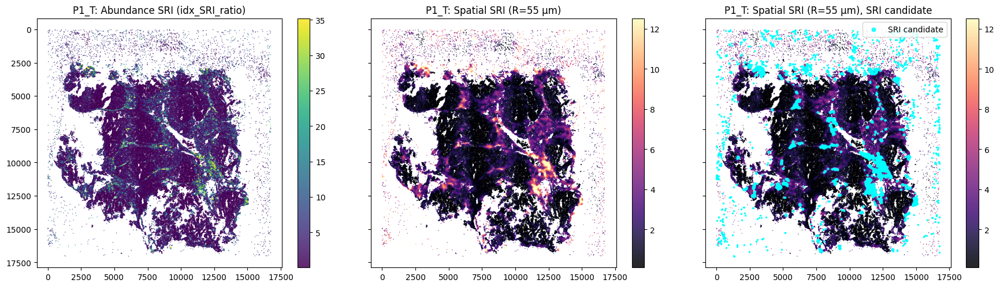

...

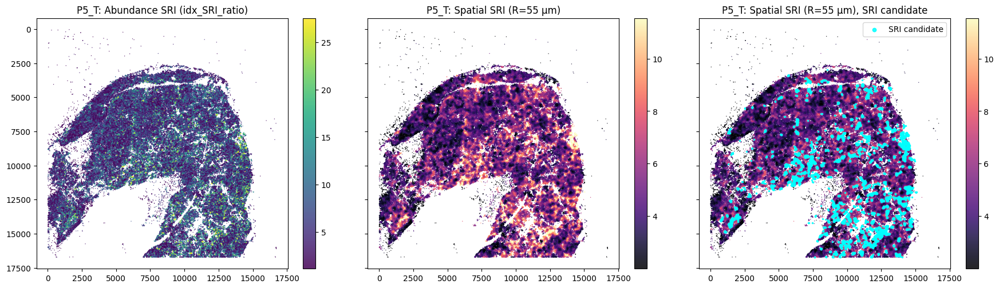

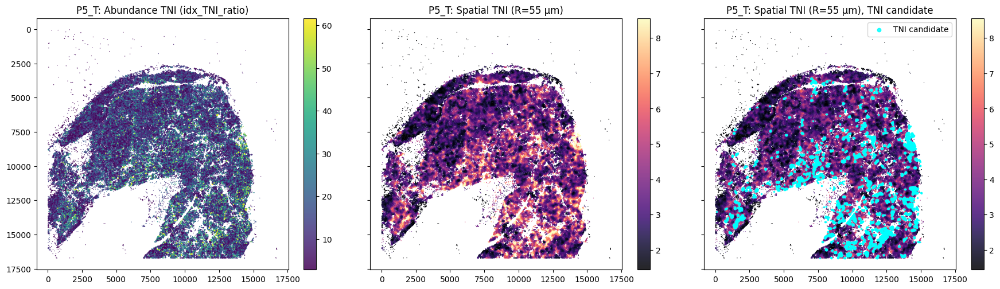

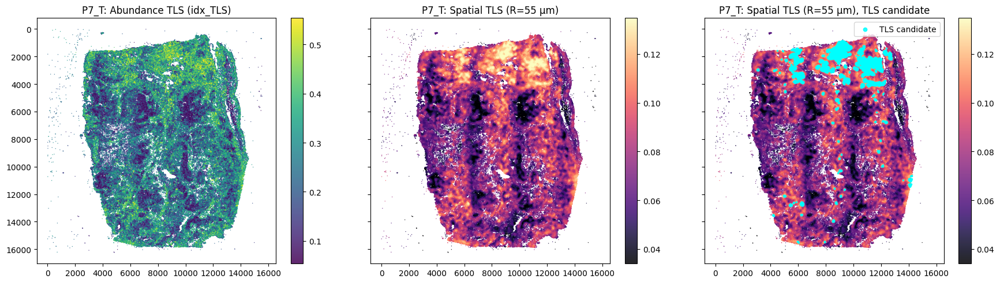

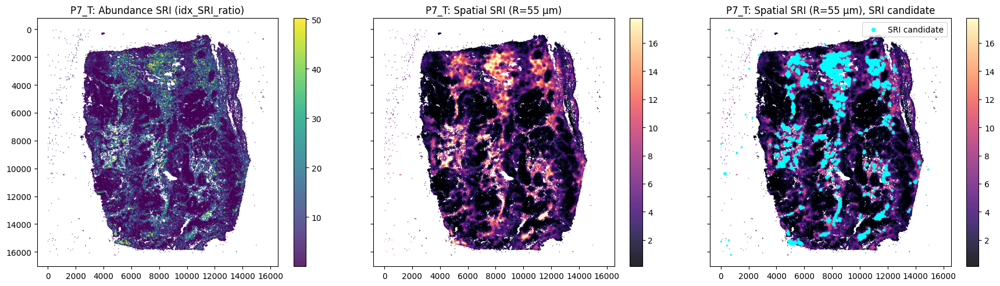

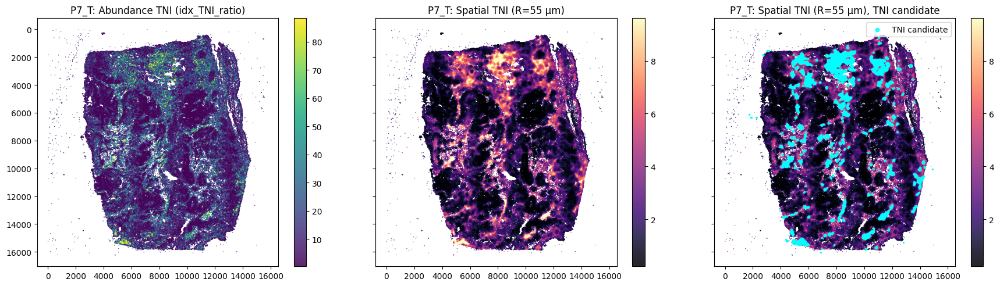

In [7]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)


def tls_score_row(df, sample: str) -> dict:
    a = df["idx_TLS"].to_numpy(dtype=float)
    s = df["idx_TLS_spatial"].to_numpy(dtype=float)
    a_hi = a >= np.percentile(a, 95)
    s_hi = df["tls_candidate"].fillna(False).astype(bool).to_numpy()
    inter = int(np.logical_and(a_hi, s_hi).sum())
    union = int(np.logical_or(a_hi, s_hi).sum())
    n_a = int(a_hi.sum())
    return {
        "sample": sample,
        "n": int(len(df)),
        "TLS_mean": float(np.mean(a)),
        "TLS_median": float(np.median(a)),
        "TLS_p95": float(np.percentile(a, 95)),
        "TLS_max": float(np.max(a)),
        "TLS_spatial_mean": float(np.mean(s)),
        "TLS_spatial_median": float(np.median(s)),
        "TLS_spatial_p95": float(np.percentile(s, 95)),
        "TLS_spatial_max": float(np.max(s)),
        "pearson": float(np.corrcoef(a, s)[0, 1]),
        "spearman": float(pd.Series(a).corr(pd.Series(s), method="spearman")),
        "top5_jaccard": (inter / union) if union else float("nan"),
        "abundance_top5_also_spatial_top5": (inter / n_a) if n_a else float("nan"),
        "TLS_spatial_mean_in_abundance_top5": float(s[a_hi].mean()) if n_a else float("nan"),
        "TLS_mean_in_spatial_top5": float(a[s_hi].mean()) if s_hi.any() else float("nan"),
    }


quant_rows = [tls_score_row(df, sample) for sample, df in niche_frames.items()]
tls_quant = pd.DataFrame(quant_rows)
tls_quant_path = fig_dir / "tls_score_summary.csv"
tls_quant.to_csv(tls_quant_path, index=False)
print(tls_quant_path)
display(tls_quant.round(3))

for sample, df in niche_frames.items():
    fig, axes = hdni.plot_tls_abundance_vs_spatial(
        df,
        sample,
        radius_um=TLS_RADIUS_UM,
        use_entropy=False,
        split_spatial_candidates=True,
        dpi=DPI,
        save_dpi=SAVE_DPI,
        point_size=0.15,
        candidate_size=1.2,
        save_path=(fig_dir / f"{sample}_TLS_abundance_vs_spatial.png") if SAVE_FIGURES else None,
    )
    display(fig)
    plt.close(fig)

    for abundance_col, spatial_col, candidate_col, tag in (
        ("idx_SRI_ratio", "idx_SRI_spatial", "sri_candidate", "SRI"),
        ("idx_TNI_ratio", "idx_TNI_spatial", "tni_candidate", "TNI"),
    ):
        fig, axes = hdni.plot_tls_abundance_vs_spatial(
            df,
            sample,
            radius_um=TLS_RADIUS_UM,
            abundance_col=abundance_col,
            spatial_col=spatial_col,
            candidate_col=candidate_col,
            score_name=tag,
            use_entropy=False,
            split_spatial_candidates=True,
            dpi=DPI,
        save_dpi=SAVE_DPI,
        point_size=0.15,
            candidate_size=1.2,
            save_path=(fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png") if SAVE_FIGURES else None,
        )
        display(fig)
        plt.close(fig)
